<a href="https://colab.research.google.com/github/Asinjoji/Casestudy_Preprocessing_Asin/blob/main/Case_Study_Asin_Notebook_Airbnb_NYC_Preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Case Study Assessment — NYC Airbnb Data Preprocessing
### Student Name: Asin Joji
### Date:27-10-2026
This notebook is your submission template. Fill in each section — do not delete the headers. Use markdown cells for your written justifications, right next to the code that supports them.

In [4]:
import pandas as pd
url = "https://raw.githubusercontent.com/erkansirin78/datasets/master/AB_NYC_2019.csv"
df = pd.read_csv(url)
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


---
## Part 1 — Data Understanding & Quality Audit

In [5]:
# TODO: shape, dtypes, missing value summary
print("Dataset shape: ")
print(df.shape)
print("\n-----Data Types-----")
print(df.dtypes)
print("\n-----Missing Value Summary-----")
print(df.isnull().sum())


Dataset shape: 
(48895, 16)

-----Data Types-----
id                                  int64
name                               object
host_id                             int64
host_name                          object
neighbourhood_group                object
neighbourhood                      object
latitude                          float64
longitude                         float64
room_type                          object
price                               int64
minimum_nights                      int64
number_of_reviews                   int64
last_review                        object
reviews_per_month                 float64
calculated_host_listings_count      int64
availability_365                    int64
dtype: object

-----Missing Value Summary-----
id                                    0
name                                 16
host_id                               0
host_name                            21
neighbourhood_group                   0
neighbourhood                  

In [6]:
# TODO: check for values that are technically present but don't make real-world sense
print("Prices of zero or less:", (df["price"] <= 0).sum())
print("Minimum nights of zero or less:", (df["minimum_nights"] <= 0).sum())
print("Availability outside 0–365 days:",(~df["availability_365"].between(0, 365)).sum())
print("Latitude outside NYC bounds:",(~df["latitude"].between(40.4, 41.0)).sum())
print("Longitude outside NYC bounds:",(~df["longitude"].between(-74.3, -73.6)).sum())

print(df[["price", "minimum_nights", "availability_365"]].agg(["min", "max"]))

Prices of zero or less: 11
Minimum nights of zero or less: 0
Availability outside 0–365 days: 0
Latitude outside NYC bounds: 0
Longitude outside NYC bounds: 0
     price  minimum_nights  availability_365
min      0               1                 0
max  10000            1250               365


In [7]:
# TODO: duplicate check
print("Exact duplicate rows:", int(df.duplicated().sum()))
print("Duplicate listing IDs:", int(df["id"].duplicated().sum()))

Exact duplicate rows: 0
Duplicate listing IDs: 0


**Written notes — what did you find, and what looks suspicious?**

1.Listings with a price of $0.

2.Listings with 0 or negative minimum nights.

3.Extreme value bounds (like extreme minimum_nights or availability_365 issues)

---
## Part 2 — Missing Value Diagnosis & Treatment

In [8]:
# TODO: investigate missingness pattern(s) across columns
print(df.isna().sum())


print("Review columns missing on the same rows:",df["last_review"].isna().equals(df["reviews_per_month"].isna()))

print("Listings with no reviews and no review date:",((df["number_of_reviews"] == 0) & df["last_review"].isna()).sum())

id                                    0
name                                 16
host_id                               0
host_name                            21
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                       10052
reviews_per_month                 10052
calculated_host_listings_count        0
availability_365                      0
dtype: int64
Review columns missing on the same rows: True
Listings with no reviews and no review date: 10052


**Written justification — MCAR / MAR / MNAR classification per column, and your reasoning:**

last_review & reviews_per_month (MAR / MNAR): Missing deterministically on the exact same 10,052 rows where number_of_reviews is 0. The missingness is fully explained by an observed variable.

name & host_name (MCAR): Missing in very few rows (16 and 21 respectively) with no logical pattern, likely due to completely random data-entry omissions or system glitches during registration

In [9]:
# TODO: apply your chosen treatment(s)

clean_df = df.copy()
clean_df["has_review_history"] = (clean_df["number_of_reviews"] > 0).astype(int)
clean_df["reviews_per_month"] = clean_df["reviews_per_month"].fillna(0)
clean_df["last_review"] = clean_df["last_review"].fillna("no_review")
clean_df["name"] = clean_df["name"].fillna("Unknown listing name")
clean_df["host_name"] = clean_df["host_name"].fillna("Unknown host")

print(clean_df.isna().sum())

id                                0
name                              0
host_id                           0
host_name                         0
neighbourhood_group               0
neighbourhood                     0
latitude                          0
longitude                         0
room_type                         0
price                             0
minimum_nights                    0
number_of_reviews                 0
last_review                       0
reviews_per_month                 0
calculated_host_listings_count    0
availability_365                  0
has_review_history                0
dtype: int64


**Written justification — why this treatment for each column, and what you'd risk with `dropna()` instead:**


name & host_name (MCAR): Missing completely at random in very few rows. Imputed with placeholders ('Unknown listing name' / 'Unknown host') because removing them via dropna() would throw away valid geospatial and price data.
last_review & reviews_per_month (MAR/MNAR): Missing systematically on the same 10,052 rows because the listings have no reviews. We imputed them with 'no_review' / 0 and added an indicator variable to keep the properties for modeling.
Risks of dropna(): Deleting these rows would discard over 20.5% of the dataset, causing severe sample size reduction and introducing bias toward older, highly reviewed listings.

---
## Part 3 — Outlier Detection & Treatment

In [10]:
import matplotlib.pyplot as plt

Price upper limit: 334.0
Number of price outliers: 2972
Minimum-nights upper limit: 11.0
Number of minimum-nights outliers: 6607


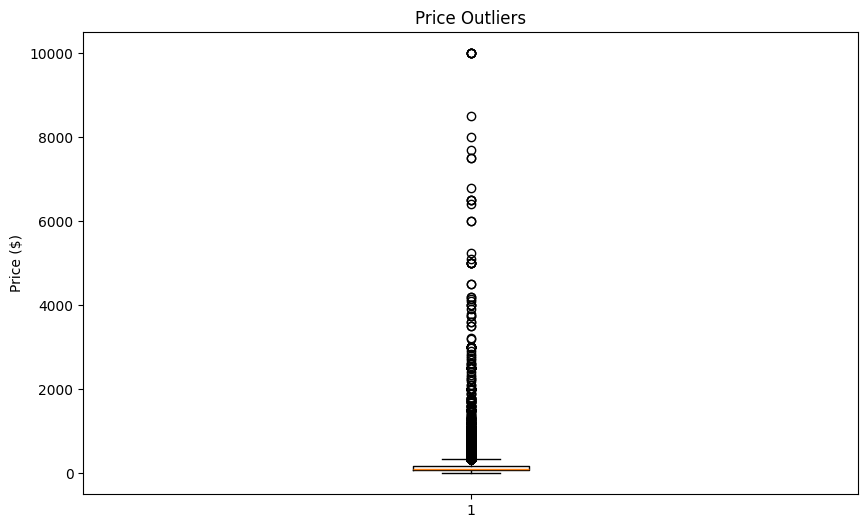

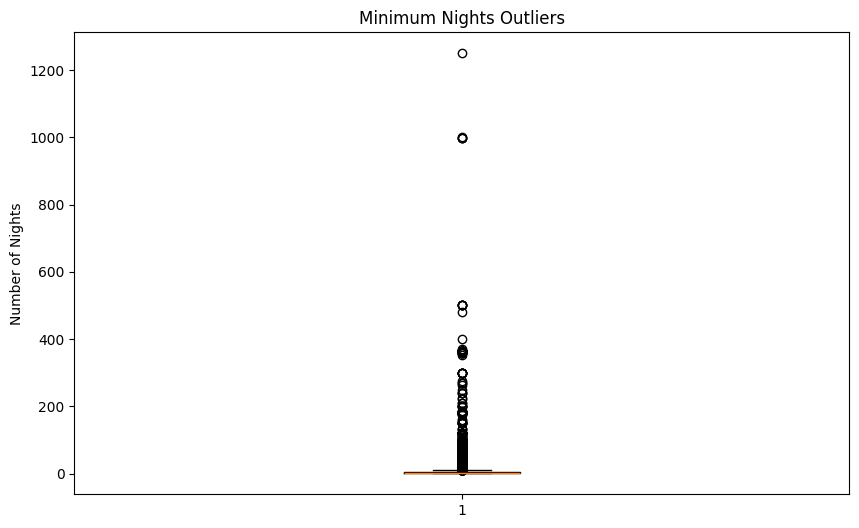

In [11]:
# TODO: detect outliers in at least two numeric columns

Q1 = clean_df["price"].quantile(0.25)
Q3 = clean_df["price"].quantile(0.75)
IQR = Q3 - Q1
upper_limit = Q3 + 1.5 * IQR

price_outliers = clean_df[clean_df["price"] > upper_limit]

print("Price upper limit:", upper_limit)
print("Number of price outliers:", len(price_outliers))

Q1 = clean_df["minimum_nights"].quantile(0.25)
Q3 = clean_df["minimum_nights"].quantile(0.75)
IQR = Q3 - Q1
upper_limit = Q3 + 1.5 * IQR

night_outliers = clean_df[clean_df["minimum_nights"] > upper_limit]

print("Minimum-nights upper limit:", upper_limit)
print("Number of minimum-nights outliers:", len(night_outliers))


plt.figure(figsize=(10, 6))
plt.boxplot(clean_df["price"])
plt.title("Price Outliers")
plt.ylabel("Price ($)")
plt.show()


plt.figure(figsize=(10, 6))
plt.boxplot(clean_df["minimum_nights"])
plt.title("Minimum Nights Outliers")
plt.ylabel("Number of Nights")
plt.show()

**Written justification — for each outlier group, is it an error or a genuine listing? What evidence supports your call?**

* **Price Outliers (up to $10,000): Genuine Listings**
  * **Evidence:** NYC has highly luxury penthouses, townhouses, and large properties (especially in Manhattan/Brooklyn) that naturally command premium prices. While they skew distributions, they are real, valid market data rather than data entry errors.

* **Minimum Nights Outliers (up to 1,250 nights): Mix of Errors and Policy-driven Listings**
  * **Evidence:** While some long minimum nights represent standard monthly or corporate mid-term rentals, values exceeding 365 nights (up to 1,250 nights) are highly unrealistic and likely represent data entry errors or hosts deliberately blocking their calendars to bypass local short-term renting regulations.

In [12]:
# TODO: apply treatment consistent with your judgment above

model_df = clean_df[clean_df["price"] > 0].copy()

print("Rows before:", len(clean_df))
print("Rows after:", len(model_df))

Rows before: 48895
Rows after: 48884


---
## Part 4 — Feature Engineering & Encoding

In [13]:
# TODO: encode categorical columns appropriately
categorical_columns = ["neighbourhood_group", "neighbourhood", "room_type"]
model_df[categorical_columns].head()

,neighbourhood_group,neighbourhood,room_type
0,Brooklyn,Kensington,Private room
1,Manhattan,Midtown,Entire home/apt
2,Manhattan,Harlem,Private room
3,Brooklyn,Clinton Hill,Entire home/apt
4,Manhattan,East Harlem,Entire home/apt


In [17]:
# TODO: engineer at least two new features
model_df["availability_share"] = model_df["availability_365"] / 365
model_df["stay_type"] = "short stay"
model_df.loc[model_df["minimum_nights"] > 7, "stay_type"] = "long stay"

model_df[["availability_share", "stay_type"]].head()

,availability_share,stay_type
0,1.000000,short stay
1,0.972603,short stay
2,1.000000,short stay
3,0.531507,short stay
4,0.000000,long stay


**Written justification — why these features, and which column(s) should NOT be used to predict price, and why:**

Why these engineered features?

availability_share: Standardizes raw available days into an active market proportion, reflecting occupancy and supply elasticity.
stay_type: Captures behavioral and pricing differences between short-term (≤7 days) and mid/long-term bookings.
Columns NOT to use & why:

id & host_id: Database keys with zero real-world economic meaning; using them causes severe overfitting.
name & host_name: Unstructured text data with high cardinality that introduces noise.
last_review: High-volume missing timestamps that act as timelines rather than generalizable price predictors.

---
## Part 5 — Build a Reusable Preprocessing Pipeline

In [18]:
# TODO: train/test split (before fitting anything)
from sklearn.model_selection import train_test_split

# Remove columns we don't want to use as predictors
X = model_df.drop(columns=[
    "price", "id", "host_id", "name", "host_name", "last_review"
])

# Price is what we want to predict
y = model_df["price"]

# Split the data: 80% for training and 20% for testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 39107
Test rows: 9777


In [19]:
# TODO: build Pipeline combining your cleaning, imputation, encoding, scaling steps
from sklearn.model_selection import train_test_split
import pandas as pd

X = model_df[[
    "neighbourhood_group",
    "room_type",
    "minimum_nights",
    "number_of_reviews",
    "availability_365"
]]

y = model_df["price"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

for column in ["neighbourhood_group", "room_type"]:
    common_value = X_train[column].mode()[0]
    X_train[column] = X_train[column].fillna(common_value)
    X_test[column] = X_test[column].fillna(common_value)

for column in ["minimum_nights", "number_of_reviews", "availability_365"]:
    middle_value = X_train[column].median()
    X_train[column] = X_train[column].fillna(middle_value)
    X_test[column] = X_test[column].fillna(middle_value)

# Turn text categories into numeric columns
X_train = pd.get_dummies(X_train)
X_test = pd.get_dummies(X_test)

# Make sure both sets have the same columns
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print("Training data shape:", X_train.shape)
print("Test data shape:", X_test.shape)

Training data shape: (39107, 11)
Test data shape: (9777, 11)


---
## Part 6 — Written Reflection

1. Missing review data often means a listing has no reviews, so I kept those listings and filled the missing values.
2. I removed listings with zero price. Other unusually high values may be real, so I kept them.
3. Since this data is from 2019, a price model should be checked with newer data before use.